In [1]:
import os 
import json 
from collections import defaultdict
from typing import List, Dict, Any
import re

papers = [11, 13, 14, 15, 16, 17, 18, 19, 20, 100] # read the annotated overlapping paper IDs 
overlap_path = "../../annotated_data/citation_annotations/annotations/overlap"
ann_path = "../../annotated_data/citation_annotations/annotations"
text_folder = "../../to_annotate"
total_data = []

for files in os.listdir(overlap_path):
    if files.endswith(".json"):
        file_path = os.path.join(overlap_path, files)
        with open(file_path, "r", encoding="utf-8") as f:
            data = json.load(f)
        for item in data:
            filename = item["file"]
            with open(os.path.join(text_folder, filename), "r", encoding="utf-8") as f:
                full_text = f.read()
            total_data.append({"file": item["file"], "start": item["start"], "end": item["end"], "label": item["label"], 'text': item['text'], 'full_text': full_text.split("References")[0]})
    

for ann in os.listdir(ann_path):
    print("Processing folder:", ann)
    for file in os.listdir(os.path.join(ann_path, ann)):
        if file.endswith(".json") and int(file.split("_")[1].split(".")[0]) not in papers:    
            file_path = os.path.join(ann_path, ann, file)
            with open(file_path, "r", encoding="utf-8") as f:
                data = json.load(f)
            for item in data:
                filename = item["file"]
            with open(os.path.join(text_folder, filename), "r", encoding="utf-8") as f:
                full_text = f.read()
            total_data.append({"file": item["file"], "start": item["start"], "end": item["end"], "label": item["label"], 'text': item['text'], 'full_text': full_text.split("References")[0]})
        
with open("../../annotated_data/goldset_sorted.json", "r", encoding="utf-8") as f:
    data = json.load(f)

for item in data:
    for label in item:
        filename = label["filename"]
        with open(os.path.join(text_folder, filename), "r", encoding="utf-8") as f:
            full_text = f.read()
        total_data.append({"file": label["filename"], "start": label["start"], "end": label["end"], "label": label["label"], 'text': label['text'], 'full_text': full_text.split("References")[0]})


_PAPER_NUM_RE = re.compile(r"paper_(\d+)\.txt")

def _paper_key(filename: str) -> int:
    """
    Extract numeric index from 'paper_n.txt' for sorting.
    Falls back to +inf if pattern doesn't match.
    """
    m = _PAPER_NUM_RE.match(filename)
    return int(m.group(1)) if m else float("inf")

def group_spans_by_file(records: List[Dict[str, Any]]):
    grouped = defaultdict(list)

    for r in records:
        grouped[r["file"]].append({
            "start": int(r["start"]),
            "end": int(r["end"]),
            "label": r["label"],
            "text": r['text'],
            "full_text": r['full_text']
        })

    # Sort by numeric paper index
    sorted_grouped = dict(
        sorted(grouped.items(), key=lambda item: _paper_key(item[0]))
    )

    return sorted_grouped
total_data = group_spans_by_file(total_data)

Processing folder: Iman
Processing folder: Ekaterina
Processing folder: overlap
Processing folder: Iraa
Processing folder: Ed


In [4]:
#train and eval split
import random
import re
from typing import Dict, List, Any, Tuple
import json 

PaperData = Dict[str, List[Dict[str, Any]]]

_PAPER_RE = re.compile(r"paper_(\d+)\.txt$")

def paper_num(name: str) -> int:
    m = _PAPER_RE.search(name)
    return int(m.group(1)) if m else 10**18  # unknowns go to end

def split_by_paper(
    data_by_paper: PaperData,
    train_ratio: float = 0.5,
    dev_ratio: float = 0.5,
    eval_ratio: float = 0,
    seed: int = 42,
) -> Tuple[PaperData, PaperData, PaperData]:
    assert abs((train_ratio + dev_ratio + eval_ratio) - 1.0) < 1e-9

    keys = sorted(data_by_paper.keys(), key=paper_num)

    rng = random.Random(seed)
    rng.shuffle(keys)

    n = len(keys)
    n_train = int(n * train_ratio)
    n_dev = int(n * dev_ratio)
    # eval gets the remainder to avoid rounding issues
    train_keys = keys[:n_train]
    dev_keys = keys[n_train:n_train + n_dev]
    eval_keys = keys[n_train + n_dev:]

    train = {k: data_by_paper[k] for k in train_keys}
    dev = {k: data_by_paper[k] for k in dev_keys}
    eval_ = {k: data_by_paper[k] for k in eval_keys}

    return train, dev, eval_

eval_data, for_synth_data, _ = split_by_paper(total_data)

def save_split(split: dict, path: str):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(split, f, ensure_ascii=False, indent=2)


In [1]:
import json 

with open("../samples/for_synth_sampling.json", 'r') as f:
    for_synth_data = json.load(f)

with open("../samples/for_eval.json", 'r') as f:
    for_eval = json.load(f)

total_data = for_synth_data | for_eval
len(total_data)

88

### Real samples profiling:
- length of spans/token count
- average position in the document -> variance/std
- semantic similarity

In [2]:
coherence_samples = []
unsupp_claim = []
lack_synth = []
format = []

for ann in total_data:
    for item in total_data[ann]: 
        if item['label'].lower() == 'coherence':
            coherence_samples.append(item)
        elif item['label'].lower() == 'unsupported claim':
            unsupp_claim.append(item)
        elif item['label'].lower() == 'lacks synthesis':
            lack_synth.append(item)
        elif item['label'].lower() == 'format':
            format.append(item)

print("Annotated data stats:")
print(f"{len(coherence_samples)} Coherence samples")
print(f"{len(unsupp_claim)} Unsupported claim samples")
print(f"{len(lack_synth)} Lacks Synthesis samples")
print(f"{len(format)} Format samples")

Annotated data stats:
24 Coherence samples
104 Unsupported claim samples
27 Lacks Synthesis samples
32 Format samples


In [3]:
import numpy as np

def center_ratio(doc, start, end): # computes where a span is in the document producing a number between 0 t0 1, where 0 = start and 1 = end
    if len(doc) == 0:
        return None
    if start is None or end is None:
        return None
    if start < 0 or end < 0:
        return None

    center = (start + end) / 2.0
    return center / len(doc) # ratio of center position to length of document


def position_stats(samples, doc_key="full_text", start_key="start", end_key="end"):
    positions = [] # center positions

    for s in samples:
        r = center_ratio(s[doc_key], s[start_key], s[end_key])
        if r is None:
            continue
        positions.append(r)


    out = {
        "count": len(positions),
        "mean": round(np.mean(positions), 4),           # mean center position
        "median": round(np.median(positions), 4),       # median center position
        "std": round(np.std(positions), 4),             # standard dev center position
        "variance": round((np.std(positions)**2), 4),
        "p10": round(np.percentile(positions, 10), 4),  
        "p25": round(np.percentile(positions, 25), 4),
        "p75": round(np.percentile(positions, 75), 4),
        "p90": round(np.percentile(positions, 90), 4),
    }

    return out

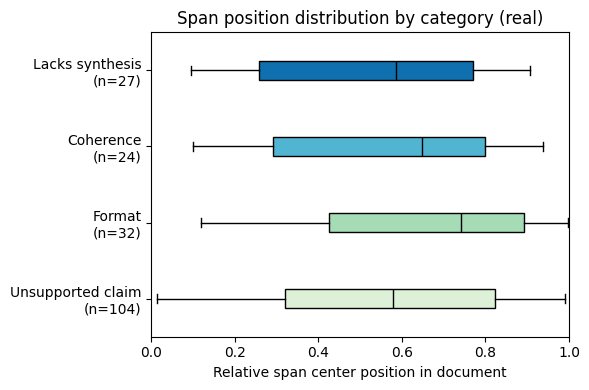

Saved: results/real/real_all_categories_center_pos_box.png


In [37]:
import matplotlib.pyplot as plt
import os

def position_box(samples, doc_key="full_text", start_key="start", end_key="end"):
    """
    Returns raw relative span center positions in [0, 1] for box plot.
    """
    positions = []
    for s in samples:
        r = center_ratio(s[doc_key], s[start_key], s[end_key])
        if r is None:
            continue
        positions.append(r)

    return {"positions": positions, "count": len(positions)}


def plot_position_boxplot_all(
    pos_by_group,
    folder,
    top_k=None,
    group_name="Group",
    title="Span position distribution by category",
    filename="all_groups_center_pos_box.png",
    vert=False
):
    groups = list(pos_by_group.keys())

    if top_k is not None:
        groups = sorted(
            groups,
            key=lambda g: pos_by_group[g].get("count", 0),
            reverse=True
        )[:top_k]

    data = []
    labels = []
    counts = []

    for g in groups:
        vals = pos_by_group[g].get("positions", [])
        if not vals:
            print(f"Skipping {group_name}={g}: no data")
            continue
        data.append(vals)
        labels.append(g)
        counts.append(pos_by_group[g].get("count", len(vals)))

    if not data:
        print("No groups had data; nothing to plot.")
        return

    tick_labels = [f"{lab}\n(n={n})" for lab, n in zip(labels, counts)]

    cmap = plt.get_cmap("GnBu")
    colors = cmap(np.linspace(0.15, 0.85, len(data)))

    plt.figure(figsize=(max(6, 1.2 * len(data)), 4))

    bp = plt.boxplot(
        data,
        vert=vert,
        widths=0.25,
        showfliers=True,
        patch_artist=True,
        medianprops=dict(color="black"),
    )

    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_edgecolor("black")

    plt.title(title + f" ({folder})")

    if vert:
        plt.ylabel("Relative span center position in document")
        plt.ylim(0, 1)
        plt.xticks(range(1, len(tick_labels) + 1), tick_labels, rotation=0)
    else:
        plt.xlabel("Relative span center position in document")
        plt.xlim(0, 1)
        plt.yticks(range(1, len(tick_labels) + 1), tick_labels)

    plt.tight_layout()
    os.makedirs(f"results/{folder}", exist_ok=True)
    out_path = f"results/{folder}/{filename}"
    plt.savefig(out_path, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out_path}")


categories = {
    "Unsupported claim": unsupp_claim,
    "Format": format,
    "Coherence": coherence_samples,
    "Lacks synthesis": lack_synth,
}

stats_per_category = {}
pos = {}

for category in categories:
    stats_per_category[category] = position_stats(categories[category])
    pos[category] = position_box(categories[category])

plot_position_boxplot_all(
    pos,
    group_name="Category",
    folder="real",
    title="Span position distribution by category",
    filename="real_all_categories_center_pos_box.png",
)


In [41]:
import re
import numpy as np

# very simple token/word counting
def count_words(text):
    return len(re.findall(r"\b\w+\b", text))

def count_tokens(text):
    # rough token count: words + punctuation
    return len(re.findall(r"\w+|[^\w\s]", text))

def span_length_stats(samples, span_key="text"):
    word_counts = []
    token_counts = []

    for s in samples:
        span = s[span_key]

        word_counts.append(count_words(span))
        token_counts.append(count_tokens(span))

    wc = np.array(word_counts)
    tc = np.array(token_counts)

    return {
        "lengths": word_counts,
        "count": len(wc),
        "words_mean": round(wc.mean(), 4),
        "words_median": round(np.median(wc), 4),
        "words_std": round(wc.std(), 4) ,
        "tokens_mean": round(tc.mean(), 4),
        "tokens_median": round(np.median(tc), 4),
        "tokens_std": round(tc.std(), 4),
    }
    
def plot_span_length_boxplot_all(
    length_by_category,
    folder,
    title="Span length distribution by category",
    ylabel="Number of words per span",
    filename="span_length_boxplot.png",
    vert=False,
):
    categories = list(length_by_category.keys())

    data = []
    labels = []
    counts = []

    for cat in categories:
        vals = length_by_category[cat]["lengths"]
        if not vals:
            continue
        data.append(vals)
        labels.append(cat)
        counts.append(length_by_category[cat]["count"])

    tick_labels = [f"{lab}\n(n={n})" for lab, n in zip(labels, counts)]

    cmap = plt.get_cmap("GnBu")
    colors = cmap(np.linspace(0.15, 0.85, len(data)))

    plt.figure(figsize=(max(6, 1.2 * len(data)), 3))

    bp = plt.boxplot(
        data,
        widths=0.25,
        showfliers=True,
        patch_artist=True,
        medianprops=dict(color="black"),
        vert=vert,
    )

    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_edgecolor("black")

    plt.title(title + f" ({folder})")

    if vert:
        plt.ylabel(ylabel)
        plt.xticks(range(1, len(tick_labels) + 1), tick_labels)
    else:
        plt.xlabel(ylabel)
        plt.yticks(range(1, len(tick_labels) + 1), tick_labels)

    plt.tight_layout()

    os.makedirs(f"results/{folder}", exist_ok=True)
    out_path = f"results/{folder}/{filename}"
    plt.savefig(out_path, bbox_inches="tight")
    plt.show()

    print(f"Saved: {out_path}")

real_length_per_category = {}


for category in categories:
    spans = categories[category]
    if category == "Lacks synthesis":
        spans = [entry for entry in spans if len(entry["text"].split()) <= 400]
    if category != 'Format':
        real_length_per_category[category] = span_length_stats(spans)

plot_span_length_boxplot_all(
    real_length_per_category,
    folder="real",
    title="Span length distribution by category of words",
    ylabel="Number of words per span",
    filename="real_span_length_box.png",
    vert=False
)

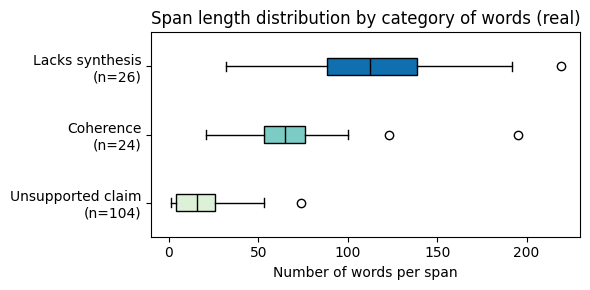

Saved: results/real/real_span_length_box.png


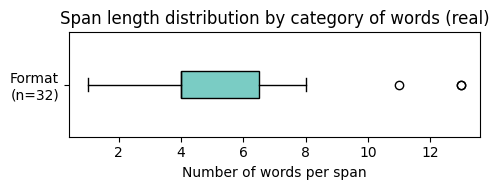

In [19]:
cat = "Format"
vals = real_length_per_category[cat]["lengths"]
count = real_length_per_category[cat]["count"]

cmap = plt.get_cmap("GnBu")
color = cmap(0.5)

plt.figure(figsize=(5, 2))

bp = plt.boxplot(
    vals,
    widths=0.25,
    showfliers=True,
    patch_artist=True,
    medianprops=dict(color="black"),
    vert=False,
)

bp["boxes"][0].set_facecolor(color)
bp["boxes"][0].set_edgecolor("black")

plt.title("Span length distribution by category of words (real)")
plt.xlabel("Number of words per span")
plt.yticks([1], [f"{cat}\n(n={count})"])
plt.tight_layout()

os.makedirs("results/real", exist_ok=True)
plt.savefig("results/real/real_span_length_format.png", bbox_inches="tight")
plt.show()

In [26]:
filename = "real_word_count.json"
with open(f"results/real/{filename}", 'w') as f:
    json.dump(real_length_per_category, f, indent=2)

### Synthetic data

In [43]:
def span_length_stats_from_category_dict(
    samples: list,
    spans_field: str = "spans",
    span_text_field: str = "span",
    group: str = "span",  # "span" or "document"
):
    if group not in ("span", "document"):
        raise ValueError("group must be 'span' or 'document'")

    word_counts = []
    token_counts = []

    for s in samples or []:
        spans = s.get(spans_field, []) or []

        if group == "span":
            for sp in spans:
                span_text = sp.get(span_text_field, "")
                wc = count_words(span_text)
                tc = count_tokens(span_text)
                word_counts.append(wc)
                token_counts.append(tc)

        else:  # group == "document"
            joined = " ".join(
                [sp.get(span_text_field, "") for sp in spans if sp.get(span_text_field)]
            )
            if not joined.strip():
                continue
            wc = count_words(joined)
            tc = count_tokens(joined)
            word_counts.append(wc)
            token_counts.append(tc)

    wc = np.array(word_counts, dtype=np.float64)
    tc = np.array(token_counts, dtype=np.float64)

    if wc.size == 0:
        return {
            "lengths": [],
            "count": 0,
            "words_mean": 0.0,
            "words_median": 0.0,
            "words_std": 0.0,
            "tokens_mean": 0.0,
            "tokens_median": 0.0,
            "tokens_std": 0.0,
        }

    return {
        "lengths": word_counts,
        "count": int(wc.size),
        "words_mean": round(float(wc.mean()), 4),
        "words_median": round(float(np.median(wc)), 4),
        "words_std": round(float(wc.std()), 4),
        "tokens_mean": round(float(tc.mean()), 4),
        "tokens_median": round(float(np.median(tc)), 4),
        "tokens_std": round(float(tc.std()), 4),
    }

In [44]:
path ="../samples/synthetic_samples_complete.json"

categories = ['lacks_synthesis', 'unsupported_claim', 'format', 'coherence']

with open(path, 'r') as f:
    synth_data = json.load(f)

In [45]:
categories = ['Unsupported claim', 'Format', 'Coherence', 'Lacks synthesis']

print("Annotated data stats:")
for category in categories:
    print(f"{len(synth_data[category])} {category} samples")


Annotated data stats:
245 Unsupported claim samples
288 Format samples
290 Coherence samples
277 Lacks synthesis samples


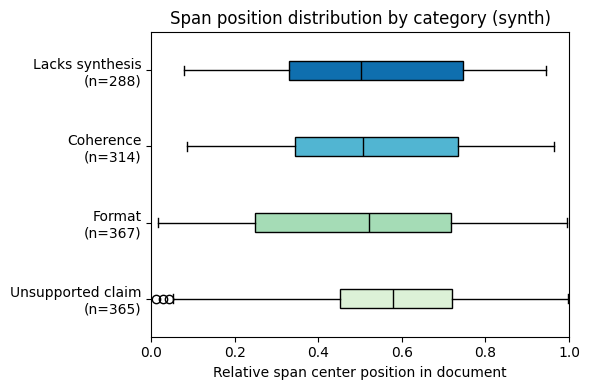

Saved: results/synth/synth_all_categories_center_pos_box.png


In [48]:
import json
import os

categories = ['Unsupported claim', 'Format', 'Coherence', 'Lacks synthesis']
stats_per_category = {}
hists = {}

for category in categories:
    flat_samples = []

    for doc_entry in synth_data.get(category, []):
        doc_text = doc_entry.get("document") or doc_entry.get("full_text")
        if not isinstance(doc_text, str) or not doc_text.strip():
            continue

        for span_entry in doc_entry.get("spans", []):
            start = span_entry["start"]
            end = span_entry["end"]

            flat_samples.append({
                "document": doc_text,
                "start": start,
                "end": end,
            })

    stats_per_category[category] = position_stats(
        flat_samples,
        doc_key='document',
        start_key='start',
        end_key='end'
    )
    hists[category] = position_box(
        flat_samples,
        doc_key='document',
        start_key='start',
        end_key='end'
    )

plot_position_boxplot_all(
    hists,
    group_name='Category',
    folder='synth',
    filename="synth_all_categories_center_pos_box.png",
)


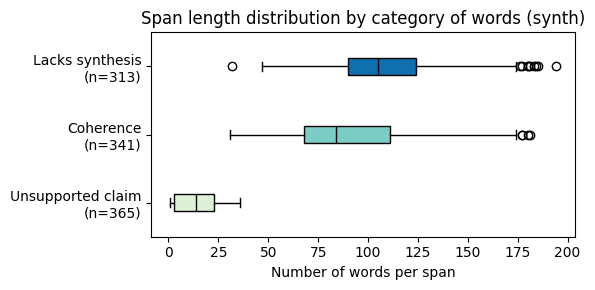

Saved: results/synth/synth_span_length_box.png


In [49]:
synth_length_per_category = {}

for category in categories:
    if category != 'Format':
        synth_length_per_category[category] = span_length_stats_from_category_dict(synth_data[category])

plot_span_length_boxplot_all(
    synth_length_per_category,
    folder="synth",
    title="Span length distribution by category of words",
    ylabel="Number of words per span",
    filename="synth_span_length_box.png",
    vert=False
)

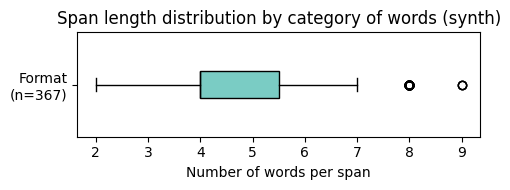

In [32]:
cat = "Format"
vals = synth_length_per_category[cat]["lengths"]
count = synth_length_per_category[cat]["count"]

cmap = plt.get_cmap("GnBu")
color = cmap(0.5)

plt.figure(figsize=(5, 2))

bp = plt.boxplot(
    vals,
    widths=0.25,
    showfliers=True,
    patch_artist=True,
    medianprops=dict(color="black"),
    vert=False,
)

bp["boxes"][0].set_facecolor(color)
bp["boxes"][0].set_edgecolor("black")

plt.title("Span length distribution by category of words (synth)")
plt.xlabel("Number of words per span")
plt.yticks([1], [f"{cat}\n(n={count})"])
plt.tight_layout()

os.makedirs("results/synth", exist_ok=True)
plt.savefig("results/synth/synth_span_length_format.png", bbox_inches="tight")
plt.show()

In [38]:
filename = "synth_word_count.json"
with open(f"results/synth/{filename}", 'w') as f:
    json.dump(synth_length_per_category, f, indent=2)

### Synth and Real in one graph:

In [58]:
import matplotlib.pyplot as plt
import os
from matplotlib.patches import Patch

def position_box(samples, doc_key="full_text", start_key="start", end_key="end"):
    """
    Real data: one span per sample.
    Returns raw relative span center positions in [0, 1] for box plot.
    """
    positions = []
    for s in samples:
        r = center_ratio(s[doc_key], s[start_key], s[end_key])
        if r is None:
            continue
        positions.append(r)

    return {"positions": positions, "count": len(positions)}


def position_box_synthetic(samples, doc_key="document", spans_key="spans"):
    """
    Synthetic data: each sample may contain multiple spans.
    Returns raw relative span center positions in [0, 1] for box plot.
    """
    positions = []
    for s in samples:
        doc = s.get(doc_key)
        if not doc:
            continue

        for sp in s.get(spans_key, []):
            start = sp.get("start")
            end = sp.get("end")
            if start is None or end is None:
                continue

            r = center_ratio(doc, start, end)
            if r is None:
                continue
            positions.append(r)

    return {"positions": positions, "count": len(positions)}


def plot_position_boxplot_real_vs_synth(
    real_pos_by_category,
    synth_pos_by_category,
    folder,
    title="Span position distribution by category",
    filename="real_vs_synth_center_pos_box.png",
    vert=False,
):
    categories = list(real_pos_by_category.keys())

    data = []
    labels = []
    positions = []
    color_keys = []

    idx = 1
    for cat in categories:
        real_vals = real_pos_by_category.get(cat, {}).get("positions", [])
        synth_vals = synth_pos_by_category.get(cat, {}).get("positions", [])

        if real_vals:
            data.append(real_vals)
            labels.append("Real")
            positions.append(idx)
            color_keys.append((cat, "Real"))

        if synth_vals:
            data.append(synth_vals)
            labels.append("Synthetic")
            positions.append(idx + 0.35)
            color_keys.append((cat, "Synthetic"))

        idx += 1.2

    if not data:
        print("No groups had data; nothing to plot.")
        return

    plt.figure(figsize=(max(10, 2.2 * len(categories)), 5))

    bp = plt.boxplot(
        data,
        positions=positions,
        vert=vert,
        widths=0.25,
        showfliers=True,
        patch_artist=True,
        medianprops=dict(color="black"),
    )

    cmap = plt.get_cmap("GnBu")

    # one base color per category
    base_colors = {
        cat: cmap(v) for cat, v in zip(categories, np.linspace(0.35, 0.9, len(categories)))
    }

    colors = []
    for cat, kind in color_keys:
        base_color = base_colors[cat]

        if kind == "Real":
        # MUCH lighter (closer to white)
            color = (
                base_color[0] + (1 - base_color[0]) * 0.5,
                base_color[1] + (1 - base_color[1]) * 0.5,
                base_color[2] + (1 - base_color[2]) * 0.5,
                1.0,
            )
        else:
            # darker than base for stronger contrast
            color = (
                base_color[0] * 0.85,
                base_color[1] * 0.85,
                base_color[2] * 0.85,
                1.0,
            )

        colors.append(color)

    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_edgecolor("black")

    plt.title(title)

    if vert:
        plt.ylabel("Relative span center position in document")
        plt.ylim(0, 1)
    else:
        plt.xlabel("Relative span center position in document")
        plt.xlim(0, 1)

        cat_centers = []
        idx = 1
        for _ in categories:
            cat_centers.append(idx + 0.6)
            idx += 1.2

        plt.yticks(cat_centers, categories, fontstyle="italic")
        plt.tick_params(axis="y", pad=10)

        for i, cat in enumerate(categories):
            y_real = 1 + i * 1.2
            y_synth = y_real + 0.35

            real_n = real_pos_by_category.get(cat, {}).get("count", 0)
            synth_n = synth_pos_by_category.get(cat, {}).get("count", 0)

            plt.text(
                -0.16, y_real,
                f"Real (n={real_n})",
                va="center",
                ha="left",
                fontsize=9,
                transform=plt.gca().get_yaxis_transform(),
                clip_on=False,
            )

            plt.text(
                -0.16, y_synth,
                f"Synth (n={synth_n})",
                va="center",
                ha="left",
                fontsize=9,
                transform=plt.gca().get_yaxis_transform(),
                clip_on=False,
            )

    legend_handles = [
        Patch(facecolor=cmap(0.55), edgecolor="black", label="Real (lighter shade)"),
        Patch(facecolor=cmap(0.9), edgecolor="black", label="Synthetic (darker shade)"),
    ]
    plt.legend(handles=legend_handles)

    plt.tight_layout()
    plt.subplots_adjust(left=0.30)

    os.makedirs(f"results/{folder}", exist_ok=True)
    out_path = f"results/{folder}/{filename}"
    plt.savefig(out_path, bbox_inches="tight")
    plt.show()

    print(f"Saved: {out_path}")

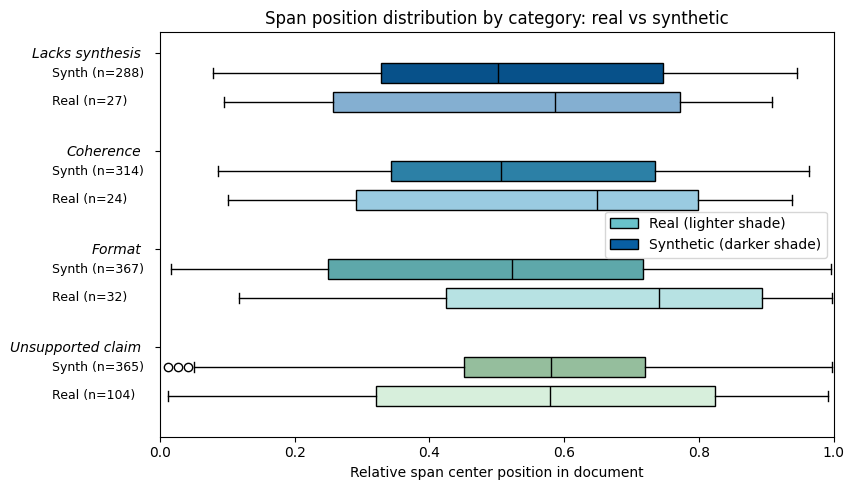

Saved: results/combined/real_vs_synthetic_all_categories_center_pos_box.png


In [59]:
import json 

categories_real = {
    "Unsupported claim": unsupp_claim,
    "Format": format,
    "Coherence": coherence_samples,
    "Lacks synthesis": lack_synth,
}

path ="../samples/synthetic_samples_complete.json"

categories = ['lacks_synthesis', 'unsupported_claim', 'format', 'coherence']

with open(path, 'r') as f:
    synth_data = json.load(f)

real_pos = {}
synth_pos = {}

for category in categories_real:
    real_pos[category] = position_box(categories_real[category])

for category in synth_data:
    synth_pos[category] = position_box_synthetic(synth_data[category])

plot_position_boxplot_real_vs_synth(
    real_pos,
    synth_pos,
    folder="combined",
    title="Span position distribution by category: real vs synthetic",
    filename="real_vs_synthetic_all_categories_center_pos_box.png",
    vert=False,
)

In [92]:
import re
import numpy as np
import matplotlib.pyplot as plt
import os
from matplotlib.patches import Patch


def count_words(text):
    return len(re.findall(r"\b\w+\b", text))


def count_tokens(text):
    return len(re.findall(r"\w+|[^\w\s]", text))


def extract_span_texts(samples, mode="real", span_key="text", spans_key="spans", synth_span_key="span"):
    """
    mode="real": expects one span per sample, e.g. sample["text"]
    mode="synthetic": expects sample["spans"] = [{"span": ...}, ...]
    """
    out = []

    for s in samples:
        if mode == "real":
            span = s.get(span_key)
            if span:
                out.append(span)

        elif mode == "synthetic":
            for sp in s.get(spans_key, []):
                span = sp.get(synth_span_key)
                if span:
                    out.append(span)

    return out


def span_length_stats_shared(
    samples,
    mode="real",
    span_key="text",
    spans_key="spans",
    synth_span_key="span",
):
    span_texts = extract_span_texts(
        samples,
        mode=mode,
        span_key=span_key,
        spans_key=spans_key,
        synth_span_key=synth_span_key,
    )

    word_counts = [count_words(span) for span in span_texts]
    token_counts = [count_tokens(span) for span in span_texts]

    if not word_counts:
        return {
            "lengths": [],
            "count": 0,
            "words_mean": 0.0,
            "words_median": 0.0,
            "words_std": 0.0,
            "tokens_mean": 0.0,
            "tokens_median": 0.0,
            "tokens_std": 0.0,
        }

    wc = np.array(word_counts)
    tc = np.array(token_counts)

    return {
        "lengths": word_counts,
        "count": len(wc),
        "words_mean": round(wc.mean(), 4),
        "words_median": round(np.median(wc), 4),
        "words_std": round(wc.std(), 4),
        "tokens_mean": round(tc.mean(), 4),
        "tokens_median": round(np.median(tc), 4),
        "tokens_std": round(tc.std(), 4),
    }

def plot_span_length_boxplot_real_vs_synth(
    real_length_by_category,
    synth_length_by_category,
    folder,
    title="Span length distribution by category",
    xlabel="Number of words per span",
    filename="real_vs_synth_span_length_box.png",
    vert=False,
    format_only=False,
):
    categories = list(real_length_by_category.keys())

    if format_only:
        categories = [cat for cat in categories if cat.lower() == "format"]
        if not categories:
            print("Format category not found; nothing to plot.")
            return

    data = []
    positions = []
    color_keys = []

    idx = 1
    for cat in categories:
        real_vals = real_length_by_category.get(cat, {}).get("lengths", [])
        synth_vals = synth_length_by_category.get(cat, {}).get("lengths", [])

        if real_vals:
            data.append(real_vals)
            positions.append(idx)
            color_keys.append((cat, "Real"))

        if synth_vals:
            data.append(synth_vals)
            positions.append(idx + 0.35)
            color_keys.append((cat, "Synthetic"))

        idx += 1.2

    if not data:
        print("No groups had data; nothing to plot.")
        return

    n_cats = len(categories)
    if vert:
        width = 6
        height = max(3, 1.3 * n_cats)
    else:
        if format_only:
            width = 5.2
            height = 1.5
        else:
            width = 8.5
            height = max(4.5, 1.45 * n_cats)

    plt.figure(figsize=(width, height))

    bp = plt.boxplot(
        data,
        positions=positions,
        widths=0.25,
        showfliers=True,
        patch_artist=True,
        medianprops=dict(color="black"),
        vert=vert,
    )

    cmap = plt.get_cmap("GnBu")

    if format_only:
        base_colors = {categories[0]: cmap(0.65)}
    else:
        base_colors = {
            cat: cmap(v) for cat, v in zip(categories, np.linspace(0.35, 0.9, len(categories)))
        }

    colors = []
    for cat, kind in color_keys:
        base_color = base_colors[cat]

        if kind == "Real":
            color = (
                base_color[0] + (1 - base_color[0]) * 0.55,
                base_color[1] + (1 - base_color[1]) * 0.55,
                base_color[2] + (1 - base_color[2]) * 0.55,
                1.0,
            )
        else:
            color = (
                base_color[0] * 0.85,
                base_color[1] * 0.85,
                base_color[2] * 0.85,
                1.0,
            )

        colors.append(color)

    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_edgecolor("black")

    plt.title(title)

    if vert:
        plt.ylabel(xlabel)
    else:
        plt.xlabel(xlabel)

        max_val = max(max(vals) for vals in data if vals)

        if format_only:
            x_limit = min(max_val + 5, 80)
            if x_limit <= 20:
                step = 5
            elif x_limit <= 40:
                step = 10
            else:
                step = 20
        else:
            x_limit = max_val + 5
            if max_val <= 50:
                step = 5
            elif max_val <= 100:
                step = 10
            elif max_val <= 300:
                step = 25
            elif max_val <= 600:
                step = 50
            else:
                step = 100

        plt.xlim(0, x_limit)
        plt.xticks(np.arange(0, x_limit + step, step))

        cat_centers = []
        idx = 1
        for _ in categories:
            if format_only:
                cat_centers.append(idx + 0.64)
            else:
                cat_centers.append(idx + 0.64)
            idx += 1.2

        plt.yticks(cat_centers, categories, fontstyle="italic")

        if format_only:
            plt.tick_params(axis="y", pad=6)
        else:
            plt.tick_params(axis="y", pad=6)

        for i, cat in enumerate(categories):
            y_real = 1 + i * 1.2
            y_synth = y_real + 0.35

            real_n = real_length_by_category.get(cat, {}).get("count", 0)
            synth_n = synth_length_by_category.get(cat, {}).get("count", 0)

            if format_only:
                text_x = -0.25
                font_size = 8
            else:
                text_x = -0.16
                font_size = 9

            plt.text(
                text_x, y_real,
                f"Real (n={real_n})",
                va="center",
                ha="left",
                fontsize=font_size,
                transform=plt.gca().get_yaxis_transform(),
                clip_on=False,
            )

            plt.text(
                text_x, y_synth,
                f"Synth (n={synth_n})",
                va="center",
                ha="left",
                fontsize=font_size,
                transform=plt.gca().get_yaxis_transform(),
                clip_on=False,
            )

    if format_only:
        legend_handles = [
            Patch(facecolor=colors[0] if len(colors) > 0 else cmap(0.55), edgecolor="black", label="Real"),
            Patch(facecolor=colors[1] if len(colors) > 1 else cmap(0.75), edgecolor="black", label="Synthetic"),
        ]
        plt.legend(handles=legend_handles, loc="lower right", fontsize=8)
    else:
        legend_handles = [
            Patch(facecolor=cmap(0.55), edgecolor="black", label="Real (lighter shade)"),
            Patch(facecolor=cmap(0.9), edgecolor="black", label="Synthetic (darker shade)"),
        ]
        plt.legend(handles=legend_handles)

    plt.tight_layout()

    if format_only:
        plt.subplots_adjust(left=0.24, right=0.98, top=0.88, bottom=0.28)
    else:
        plt.subplots_adjust(left=0.26)

    os.makedirs(f"results/{folder}", exist_ok=True)
    out_path = f"results/{folder}/{filename}"
    plt.savefig(out_path, bbox_inches="tight")
    plt.show()

    print(f"Saved: {out_path}")

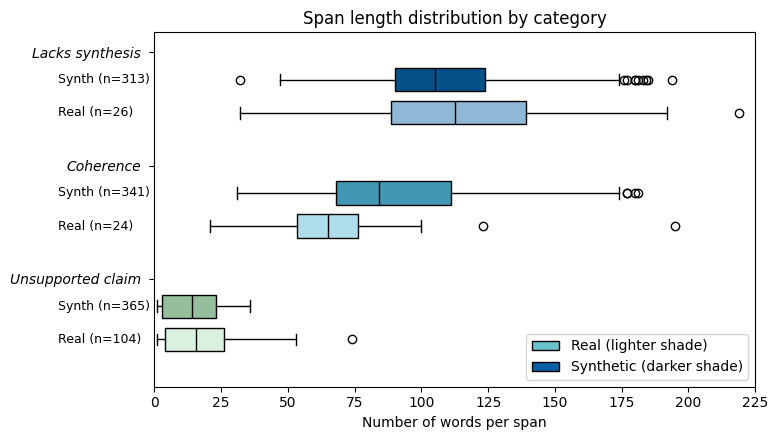

Saved: results/all/all_span_length_box.png


In [93]:
real_length_per_category = {}
synth_length_per_category = {}

for category in categories_real:
    spans = categories_real[category]
    if category == "Lacks synthesis":
        spans = [entry for entry in spans if len(entry["text"].split()) <= 400]
    if category != "Format":
        real_length_per_category[category] = span_length_stats_shared(
            spans,
            mode="real",
            span_key="text",
        )

for category in synth_data:
    spans = synth_data[category]
    if category != "Format":
        synth_length_per_category[category] = span_length_stats_shared(
            spans,
            mode="synthetic",
            spans_key="spans",
            synth_span_key="span",
        )
        
plot_span_length_boxplot_real_vs_synth(
    real_length_by_category=real_length_per_category,
    synth_length_by_category=synth_length_per_category,
    folder="all",
    title="Span length distribution by category",
    xlabel="Number of words per span",
    filename="all_span_length_box.png",
    vert=False,
)

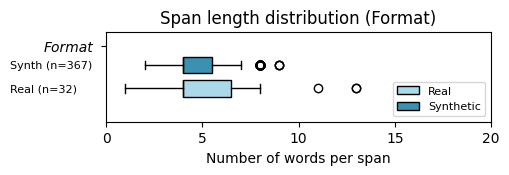

Saved: results/format_only/format_real_vs_synth_span_length_box.png


In [90]:
real_length_per_category = {}
synth_length_per_category = {}

for category in categories_real:
    spans = categories_real[category]
    if category == "Format":
        real_length_per_category[category] = span_length_stats_shared(
            spans,
            mode="real",
            span_key="text",
        )

for category in synth_data:
    spans = synth_data[category]
    if category == "Format":
        synth_length_per_category[category] = span_length_stats_shared(
            spans,
            mode="synthetic",
            spans_key="spans",
            synth_span_key="span",
        )

plot_span_length_boxplot_real_vs_synth(
    real_length_by_category={"Format": real_length_per_category["Format"]},
    synth_length_by_category={"Format": synth_length_per_category["Format"]},
    folder="format_only",
    title="Span length distribution (Format)",
    xlabel="Number of words per span",
    filename="format_real_vs_synth_span_length_box.png",
    vert=False,
    format_only=True
)